In [4]:
# 기본 분석 및 계산용 라이브러리
import pandas as pd
import numpy as np

In [9]:
# 그래프 관련 라이브러리
import matplotlib.pyplot as plt
import seaborn as sns
plt.rcParams['font.family'] = 'Malgun Gothic'   # 한글 폰트 설정: Windows
plt.rcParams['axes.unicode_minus'] = False      # 마이너스 기호 깨짐 방지

In [11]:
# 지난시간 데이터 가져오기
df1 = pd.read_excel('sample_data.xlsx', sheet_name=0)
df2 = pd.read_excel('sample_data.xlsx', sheet_name=1)

In [15]:
df1

,transaction_id,transaction_date,employee_id,customer_type,product_name,category,unit_price,quantity,discount_rate,unit_cost
0,T00001,2026-03-08,E001,중소기업,비즈니스 노트북,노트북,1250000,7,0.01,900000
1,T00002,2026-03-19,E004,소상공인,10인치 태블릿,태블릿,680000,10,0.01,469000
2,T00003,2026-03-17,E010,중소기업,데이터 분석 패키지,소프트웨어,540000,3,0.03,238000
3,T00004,2026-03-03,E007,중소기업,울트라북,노트북,1580000,1,0.00,1169000
4,T00005,2026-05-26,E009,중소기업,무선 키보드,주변기기,89000,15,0.06,52000
...,...,...,...,...,...,...,...,...,...,...
995,T00996,2026-02-18,E005,개인,오피스 라이선스,소프트웨어,220000,10,0.06,84000
996,T00997,2026-02-16,E004,소상공인,12인치 태블릿 Pro,태블릿,920000,10,0.04,653000
997,T00998,2026-03-23,E009,중소기업,데이터 분석 패키지,소프트웨어,540000,3,0.00,238000
998,T00999,2026-03-13,E005,공공기관,울트라북,노트북,1580000,9,0.13,1169000


In [27]:
df1.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 10 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   transaction_id    1000 non-null   object 
 1   transaction_date  1000 non-null   object 
 2   employee_id       1000 non-null   object 
 3   customer_type     1000 non-null   object 
 4   product_name      1000 non-null   object 
 5   category          1000 non-null   object 
 6   unit_price        1000 non-null   int64  
 7   quantity          1000 non-null   int64  
 8   discount_rate     1000 non-null   float64
 9   unit_cost         1000 non-null   int64  
dtypes: float64(1), int64(3), object(6)
memory usage: 78.3+ KB


<Axes: xlabel='discount_rate', ylabel='Count'>

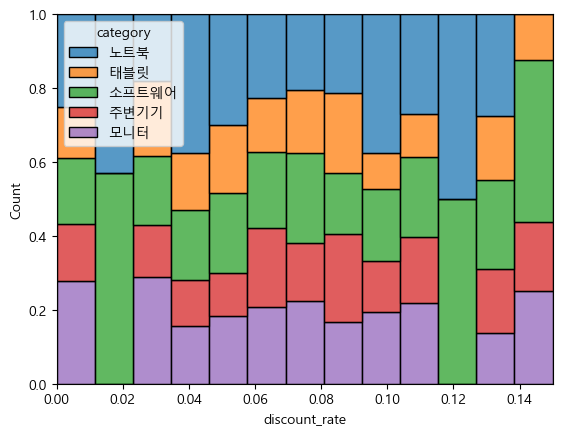

In [45]:
sns.histplot(data=df1, x='discount_rate', hue='category', multiple='fill')
# {"layer", "dodge", "stack", "fill"}

<Axes: xlabel='discount_rate', ylabel='Count'>

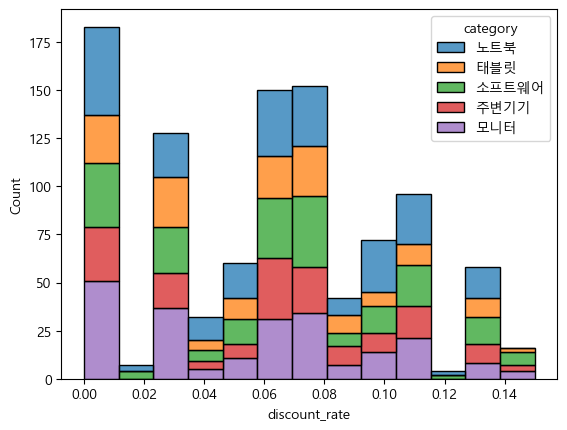

In [47]:
sns.histplot(data=df1, x='discount_rate', hue='category', multiple='stack')

In [ ]:
sns.histplot   (data=df1, x='discount_rate', hue='category', multiple='stack')

<Axes: xlabel='quantity', ylabel='unit_price'>

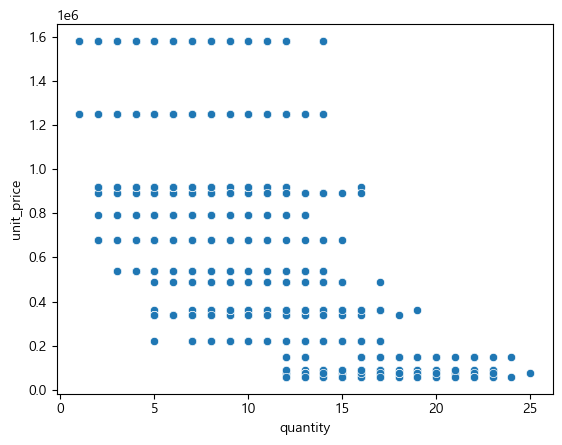

In [53]:
# 산점도
sns.scatterplot(data = df1, x='quantity', y='unit_price')  #

In [79]:
# unit_price	quantity
df1['매출액']   = df1['quantity'] * df1['unit_price']
df1['매출원가'] = df1['quantity'] * df1['unit_cost']
df1['할인액']   = df1['매출액'] * df1['discount_rate']

In [81]:
df1.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 13 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   transaction_id    1000 non-null   object 
 1   transaction_date  1000 non-null   object 
 2   employee_id       1000 non-null   object 
 3   customer_type     1000 non-null   object 
 4   product_name      1000 non-null   object 
 5   category          1000 non-null   object 
 6   unit_price        1000 non-null   int64  
 7   quantity          1000 non-null   int64  
 8   discount_rate     1000 non-null   float64
 9   unit_cost         1000 non-null   int64  
 10  매출액               1000 non-null   int64  
 11  매출원가              1000 non-null   int64  
 12  할인액               1000 non-null   float64
dtypes: float64(2), int64(5), object(6)
memory usage: 101.7+ KB


<Axes: xlabel='매출액', ylabel='할인액'>

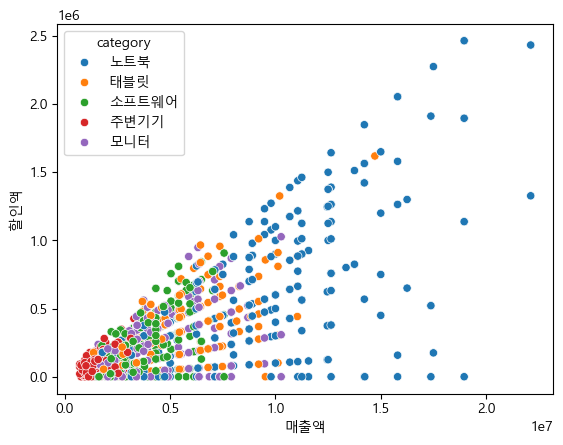

In [89]:
sns.scatterplot(data=df1, x='매출액' , y='할인액', hue='category')
sns.bubble??? (data=df1, x='매출액' , y='할인액', hue='category', 크기='4번컬럼' )

<Axes: xlabel='매출액', ylabel='Count'>

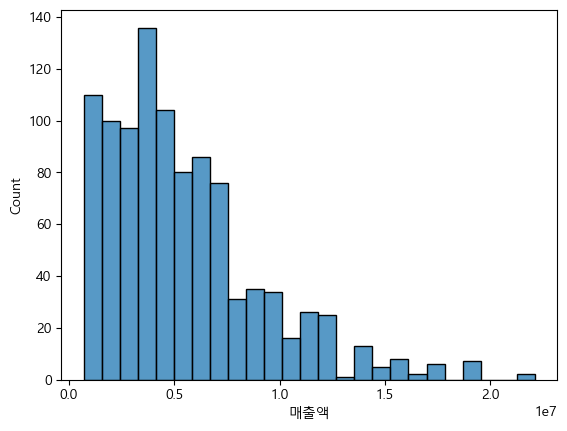

In [95]:
sns.histplot(data = df1, x=df1['매출액'])

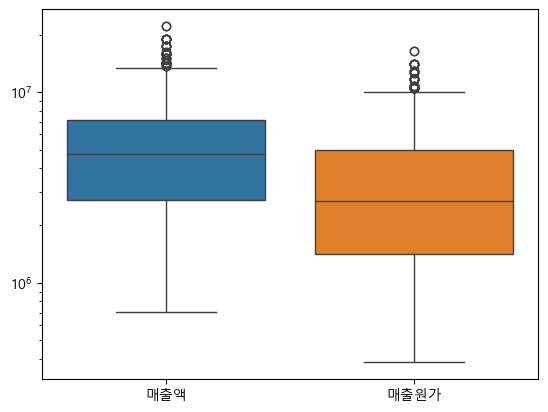

In [111]:
sns.boxplot(data = df1[['매출액','매출원가']])
plt.yscale('log') # 로그스케일

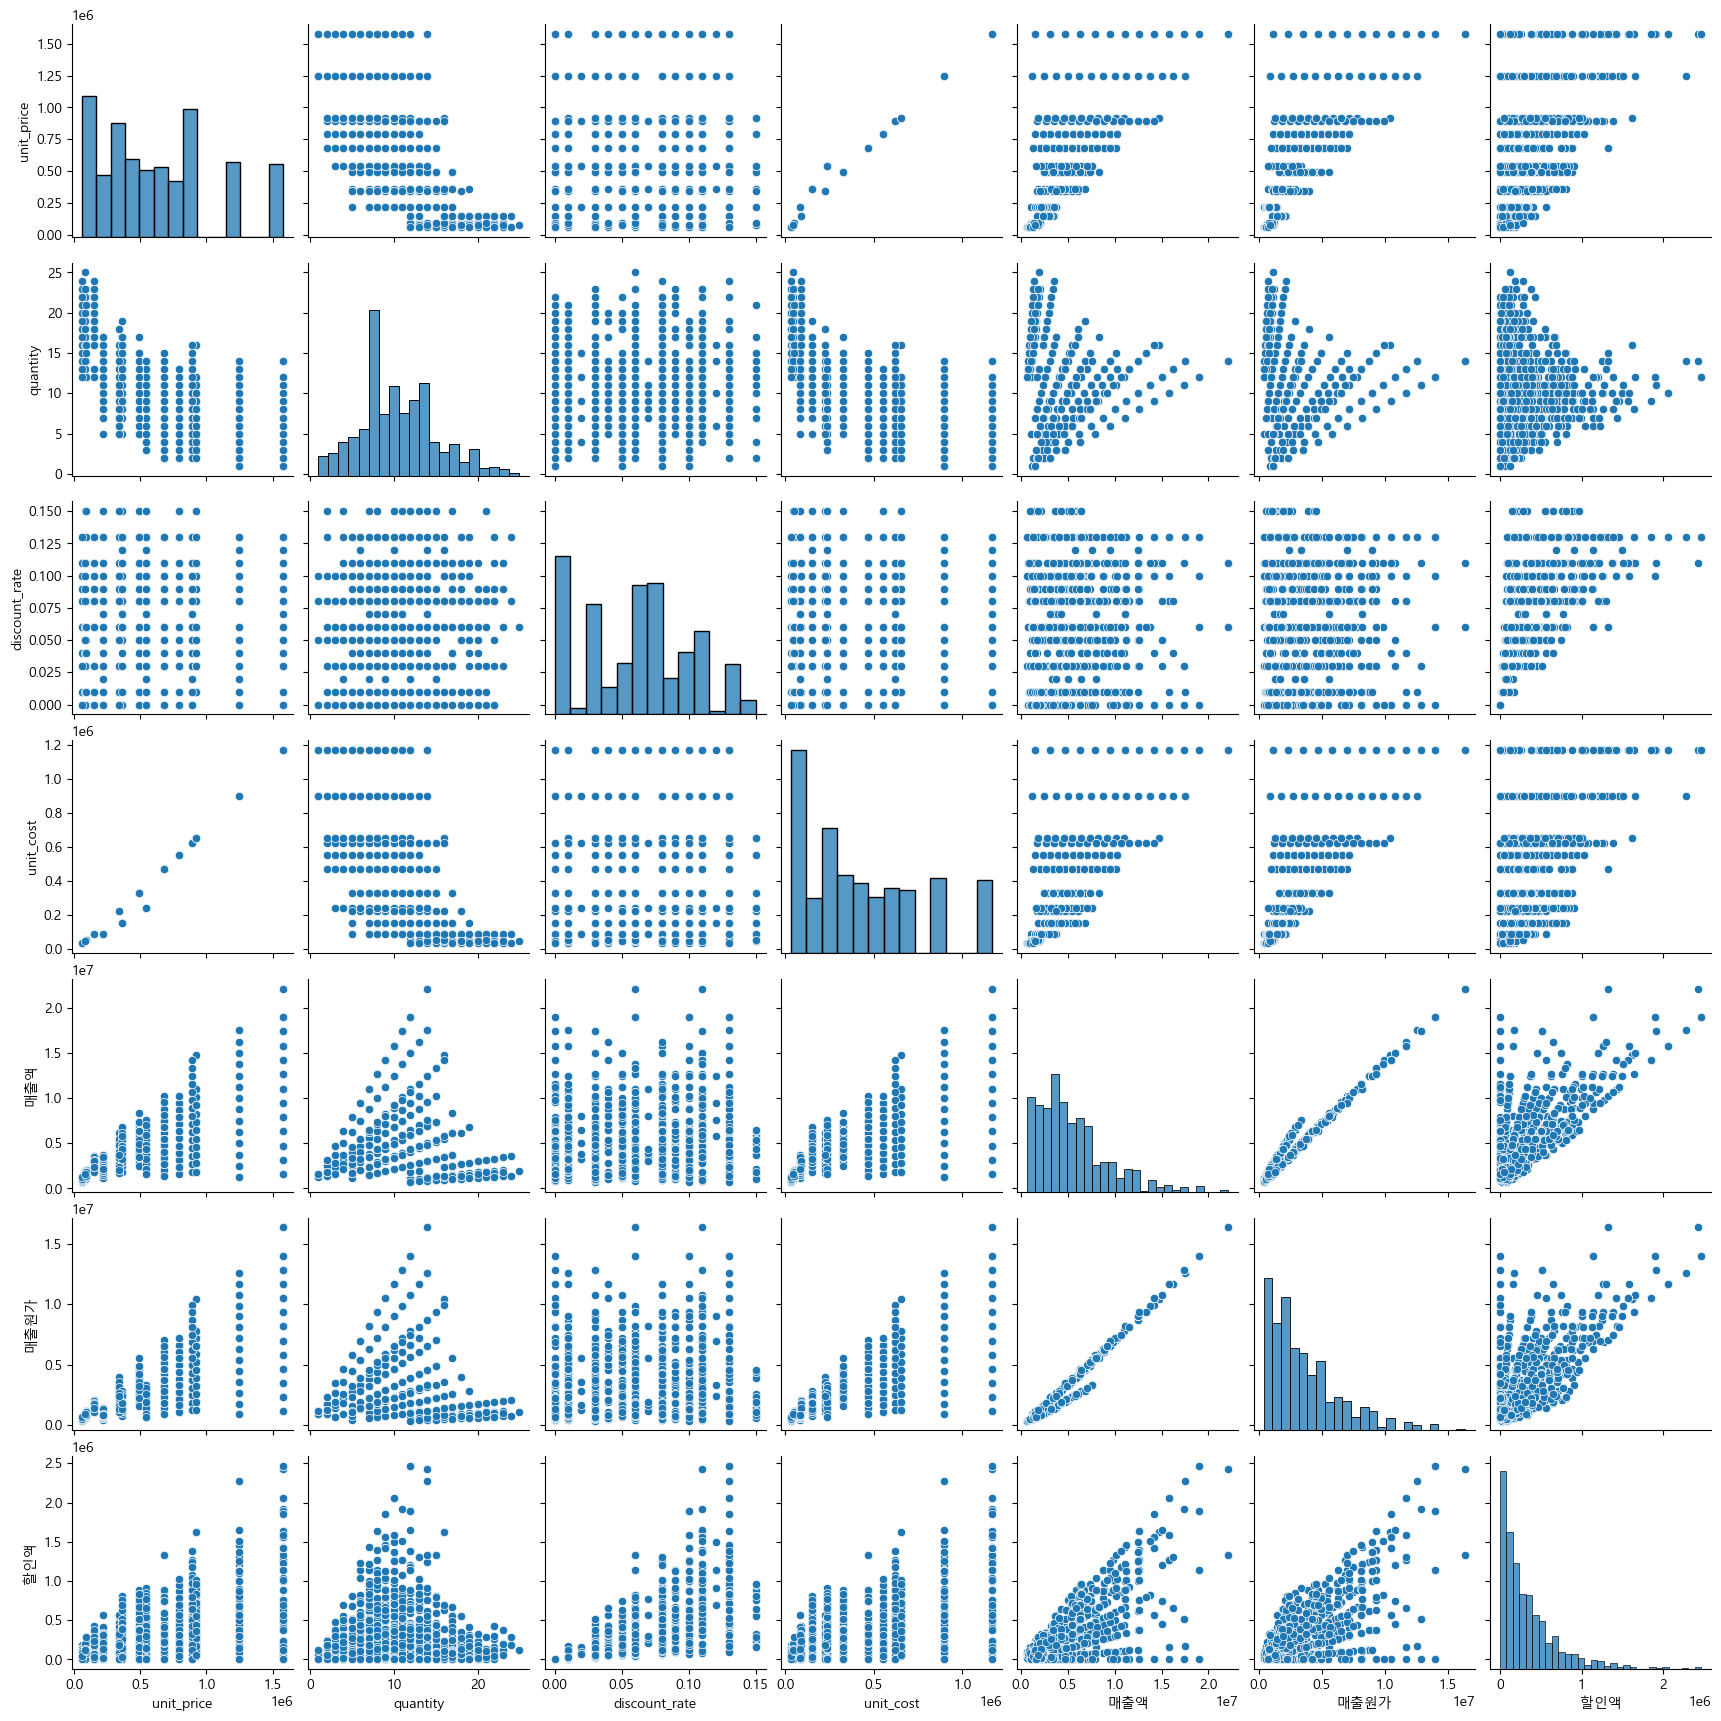

In [113]:
sns.pairplot(df1)

In [138]:
df1_grp = df1.groupby('category').agg(
    총매출액   = ('매출액', 'sum'),
    평균매출 = ('매출액', 'mean') 
).sort_values('평균매출', ascending=False)

In [140]:
df1_grp # 정렬 후

,총매출액,평균매출
category,,
노트북,2364590000,9.573239e+06
태블릿,894240000,5.806753e+06
모니터,1102510000,4.943991e+06
소프트웨어,856640000,4.021784e+06
주변기기,264364000,1.621865e+06


<Axes: xlabel='category', ylabel='총매출액'>

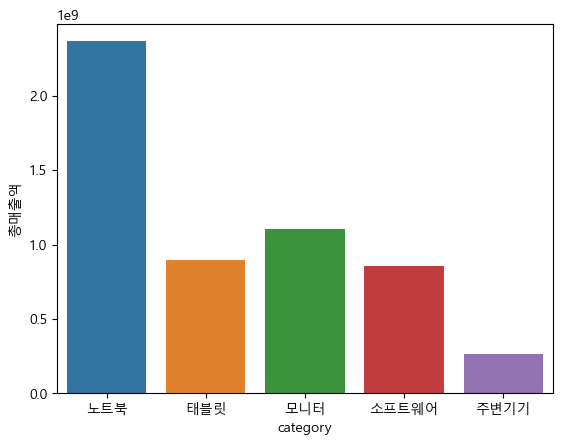

In [142]:
sns.barplot(data=df1_grp, x='category', y='총매출액', hue='category')

In [130]:
df1_grp  # 정렬 전

,총매출액,평균매출
category,,
노트북,2364590000,9.573239e+06
모니터,1102510000,4.943991e+06
소프트웨어,856640000,4.021784e+06
주변기기,264364000,1.621865e+06
태블릿,894240000,5.806753e+06


<Axes: xlabel='category', ylabel='총매출액'>

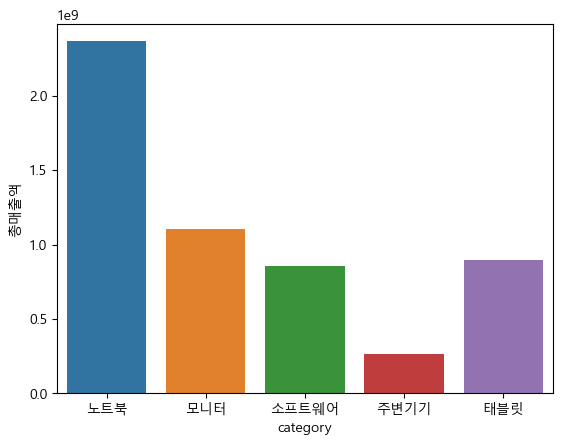

In [128]:
sns.barplot(data=df1_grp, x='category', y='총매출액', hue='category')

In [118]:
df1.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 13 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   transaction_id    1000 non-null   object 
 1   transaction_date  1000 non-null   object 
 2   employee_id       1000 non-null   object 
 3   customer_type     1000 non-null   object 
 4   product_name      1000 non-null   object 
 5   category          1000 non-null   object 
 6   unit_price        1000 non-null   int64  
 7   quantity          1000 non-null   int64  
 8   discount_rate     1000 non-null   float64
 9   unit_cost         1000 non-null   int64  
 10  매출액               1000 non-null   int64  
 11  매출원가              1000 non-null   int64  
 12  할인액               1000 non-null   float64
dtypes: float64(2), int64(5), object(6)
memory usage: 101.7+ KB
